# Teaching an audio classifier 13 new sound classes

The task was to take a pretrained 16-class Audio Spectrogram Transformer (AST) and extend it to 29 classes without it forgetting the old ones. I kept AST frozen, pulled embeddings from a few of its layers and trained a class-balanced ridge classifier on top. I also fixed some wrong old labels using the original model's confident predictions and restricted the classes by clip duration. This version got a score of 0.926.

# 🎧 Operation Night Watch: Teaching an Old Classifier New Sounds

## The story

Your company runs a network of low-power acoustic monitoring stations. The production model on these stations is an **Audio Spectrogram Transformer (AST)** that recognizes **16 everyday and wildlife sound classes**: dogs, roosters, thunderstorms, sea waves, even keyboard typing.

## The rules

1. ✅ You **must start from the provided checkpoint** (`model/`) and reuse its encoder weights. You may add parameters (extra classifier rows, adapters, …) and fine-tune any subset of weights
2. ✅ Your final model must classify **all 29 classes** (16 old + 13 new) in a single forward pass
3. ❌ No training from scratch, and no other pre-trained audio models
4. ⏱️ Keep it lightweight: everything should run on a single GPU ~ 10 mins of training time

# First things first: Set up Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import shutil
drive.mount('/content/drive')
source_path = '/content/drive/MyDrive/dataset.zip'
destination_path = '/content/dataset.zip'

shutil.copy(source_path, destination_path)

Mounted at /content/drive
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


'/content/dataset.zip'

In [2]:
!pip -q install gdown
"""import gdown, random, os
from google.colab import drive
drive.mount('/content/drive')

# dataset.zip mirrors in your IOAI-2026/AudioClassifier/data folder. Each file ID has its
# own Google Drive download quota, so we try them in random order to survive heavy load.
MIRRORS = [
    "12XaRWYDsHq3eBwrgZ0QnEOffflS_dlff",   # dataset.zip
    "1iUYDtKxXM1GSG5VNJ3r9847hqhWEiQRq",   # dataset_m2.zip
    "112F9IFfn3_UtOPwSM1cGbuAL7Ci2aBP_",   # dataset_m3.zip
]
random.shuffle('/content/drive/MyDrive/dataset.zip')"""
import gdown, random, os

ONE_GB_IN_BYTES = 10**9
file_exists_and_is_valid = os.path.exists(destination_path) and os.path.getsize(destination_path) > ONE_GB_IN_BYTES

if not file_exists_and_is_valid:
    print("🔄 Copying dataset zip from Drive to local disk space...")
    # Clean up corrupt file leftovers if they exist
    if os.path.exists(destination_path):
        os.remove(destination_path)

    # Perform the copy operation
    shutil.copy(source_path, destination_path)
    print("✅ Copy complete!")
else:
    print("👌 Valid zip file already exists locally. Skipping copy phase.")

# 4. Unzip the file into the destination folder
print("📦 Extracting dataset. Please wait...")
!unzip -q -o /content/dataset.zip -d /content/dataset_debug
print("🎉 Extraction completely finished!")

👌 Valid zip file already exists locally. Skipping copy phase.
📦 Extracting dataset. Please wait...
🎉 Extraction completely finished!


In [3]:
from pathlib import Path

LOCAL_DATA_DIR = Path("/content/dataset_debug")

if not LOCAL_DATA_DIR.exists():
    raise FileNotFoundError(
        "Dataset not found. Please run the dataset download/unzip cell first."
    )

print("Dataset found:")
for i in LOCAL_DATA_DIR.iterdir():
  print(i)

Dataset found:
/content/dataset_debug/train.csv
/content/dataset_debug/__MACOSX
/content/dataset_debug/fine_tune.csv
/content/dataset_debug/audio
/content/dataset_debug/model


# 0. Setup

What you have inside the ```/content/audioclassifier_data```:

| Artifact | Description |
|---|---|
| `model/` | Pre-trained AST checkpoint (16-class classifier) |
| `train.csv` | The retained subset of the *old* data — 16 classes, `train`/`val` splits |
| `fine_tune.csv` | The *new* data — 13 classes, `train`/`val` splits |
| `audio/` | All audio clips (5 s, mono, 16 kHz `.wav`) |


In [4]:
import json
import os
import warnings
from pathlib import Path

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Audio, HTML, display
from sklearn.manifold import TSNE
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix
from torch.utils.data import DataLoader, Dataset
from transformers import ASTFeatureExtractor, ASTForAudioClassification

warnings.filterwarnings("ignore")
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

OLD_CSV = LOCAL_DATA_DIR / "train.csv"
NEW_CSV = LOCAL_DATA_DIR / "fine_tune.csv"
CHECKPOINT = LOCAL_DATA_DIR / "model"
SR = 16_000
BATCH_SIZE = 8
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

config = json.loads((CHECKPOINT / "config.json").read_text())
old_id2label = {int(k): v for k, v in config["id2label"].items()}
NUM_OLD = len(old_id2label)
print(f"device = {DEVICE} | checkpoint knows {NUM_OLD} classes")

device = cuda | checkpoint knows 16 classes


In [5]:
old_df = pd.read_csv(OLD_CSV)

new_df = pd.read_csv(NEW_CSV)
new_df["target"] = new_df["target"]
new_id2label = dict(new_df[["target", "category"]].drop_duplicates().values)
new_id2label = {int(k): v for k, v in sorted(new_id2label.items())}

id2label = {**old_id2label, **new_id2label}            # all 29 classes
label2id = {v: k for k, v in id2label.items()}
NUM_TOTAL = len(id2label)
print(f"total classes after expansion: {NUM_TOTAL}")

total classes after expansion: 29


## 1. Meet the data

### The old world: 16 base classes

These are the classes the deployed model already recognizes. `train.csv` is the small retained subset — note how few training clips per class are left.


In [6]:
old_summary = (old_df.groupby(["target", "category", "split"]).size()
               .unstack(fill_value=0)[["train", "val"]])
print(f"old-data clips: {len(old_df)}")
old_summary

old-data clips: 491


,split,train,val
target,category,,
0,Dog,12,8
1,Rooster,12,8
2,Pig,12,8
3,Cow,22,8
4,Frog,35,23
5,Cat,12,8
6,Hen,12,8
7,Sheep,3,8
8,Crow,12,8


In [8]:
new_summary = (new_df.groupby(["target", "category", "split"]).size()
               .unstack(fill_value=0)[["train", "val"]])
print(f"new-data clips: {len(new_df)}")
new_summary

new-data clips: 792


,split,train,val
target,category,,
16,Crackling Fire,24,8
17,Axe,45,15
18,Chainsaw,45,15
19,Generator,45,15
20,Hand Saw,45,15
21,Vehicle Engine,45,15
22,Helicopter,45,15
23,Gunshot,45,15
24,Firework,45,15


## 3. Diagnostic tools: waveform & spectrogram

Here are some helpful diagnostic tools for working with audio:

- **Waveform** (amplitude vs. time) — reveals the *temporal envelope*: a gunshot is a single sharp transient, rain is a stationary wash, a cricket pulses rhythmically.
- **Log-mel spectrogram** (energy per mel-frequency band vs. time) — this is literally what the model sees. Insects concentrate energy in narrow high-frequency bands; engines sit in low-frequency harmonics; rain spreads energy everywhere.

Compare the four examples below — an impulse, an insect, a machine, and weather.


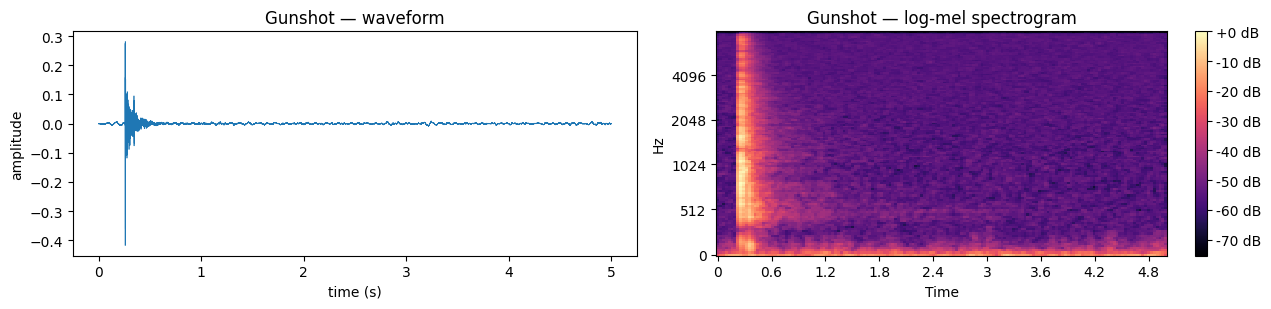

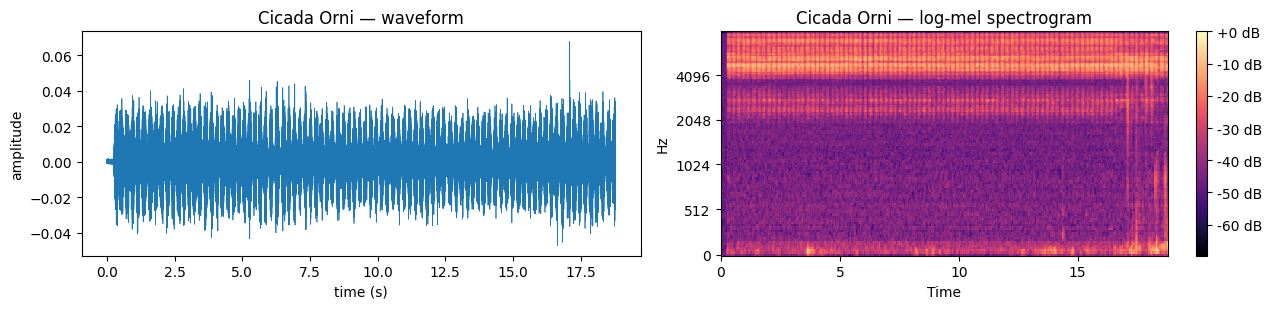

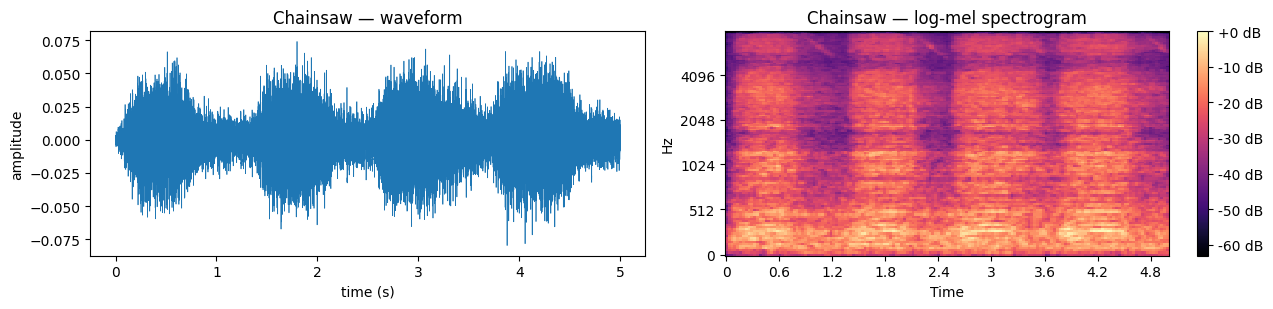

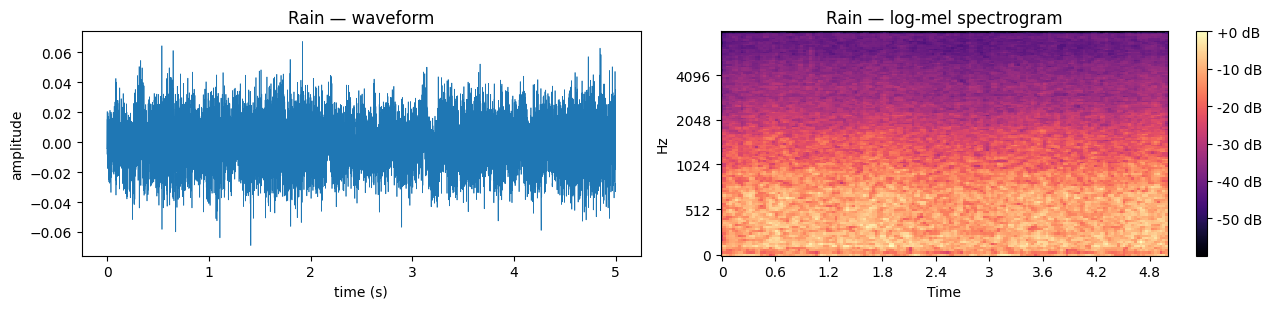

In [10]:
def plot_waveform_and_spectrogram(path, title=""):
    wav, _ = librosa.load(path, sr=SR, mono=True)
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
    axes[0].plot(np.arange(len(wav)) / SR, wav, linewidth=0.5, color="tab:blue")
    axes[0].set(title=f"{title} — waveform", xlabel="time (s)", ylabel="amplitude")
    S = librosa.feature.melspectrogram(y=wav, sr=SR, n_mels=128)
    img = librosa.display.specshow(librosa.power_to_db(S, ref=np.max), sr=SR,
                                   x_axis="time", y_axis="mel", ax=axes[1], cmap="magma")
    axes[1].set(title=f"{title} — log-mel spectrogram")
    fig.colorbar(img, ax=axes[1], format="%+2.0f dB")
    plt.tight_layout()
    plt.show()

all_df = pd.concat([old_df, new_df], ignore_index=True)
for t in [23, 26, 18, 15]:  # Gunshot, Cicada Orni, Chainsaw, Rain
    row = all_df[all_df["target"].eq(t) & all_df["split"].eq("val")].sample(1, random_state=0).iloc[0]
    plot_waveform_and_spectrogram(LOCAL_DATA_DIR / row["path"], id2label[t])

## 4. The model: Audio Spectrogram Transformer (AST)

The checkpoint in `model/` is an **Audio Spectrogram Transformer (AST)** ([Gong et al., *AST: Audio Spectrogram Transformer*, Interspeech 2021](https://arxiv.org/abs/2104.01778)). The key idea: **treat audio classification as image classification**.

![AST architecture](images/ast.png)

The pipeline:

1. The waveform is converted into a **128-band log-mel spectrogram** — a 2D "image" of shape `128 mel bins × 1024 time frames` (≈10 s, padded).
2. The spectrogram is cut into overlapping **16×16 patches**, each linearly projected to a 768-dim embedding (plus positional embeddings) — exactly like a Vision Transformer (ViT).
3. A stack of **12 Transformer encoder layers** lets every patch attend to every other patch — capturing both harmonic structure (across frequency) and temporal structure (across time).
4. The `[CLS]`-style tokens are pooled and a small **linear classification head** maps the 768-dim embedding to class logits.

Crucially, AST is initialized from **ImageNet-pre-trained ViT weights** and then pre-trained on **AudioSet** (~2M clips) before being fine-tuned for our 16 classes. That cascade of pre-training is what makes its features so strong — and what you cannot reproduce within this task's budget.

The architecture splits naturally into:
- the **encoder** (~86M parameters) — a general-purpose audio feature extractor, and
- the **head** - a tiny linear layer with 16 output rows

To support 29 classes you will need a head with 29 output rows. How you grow it — and how you fine-tune without forgetting — is the heart of this task.


# || START SOL ||

In [11]:
feature_extractor = ASTFeatureExtractor.from_pretrained(CHECKPOINT)
model = ASTForAudioClassification.from_pretrained(CHECKPOINT).to(DEVICE).eval()

total = sum(p.numel() for p in model.parameters())
head = sum(p.numel() for p in model.classifier.parameters())
print(f"total parameters:   {total / 1e6:.1f} M")
print(f"classifier head:    {head / 1e3:.1f} K  ({head / total:.3%} of the model)")

row = old_df[old_df["split"].eq("val")].iloc[0]
wav, _ = librosa.load(LOCAL_DATA_DIR / row["path"], sr=SR, mono=True)
feats = feature_extractor(wav, sampling_rate=SR, return_tensors="pt")
print(f"\nmodel input for one clip: {tuple(feats['input_values'].shape)}  (batch, time frames, mel bins)")

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

total parameters:   86.2 M
classifier head:    13.8 K  (0.016% of the model)

model input for one clip: (1, 1024, 128)  (batch, time frames, mel bins)


In [13]:
train_val = pd.concat([old_df, new_df], ignore_index=True)
test = pd.read_csv('submission.csv').drop(
        columns=["target"], errors="ignore"
    )

## Some audios are too large, so we propose this concat strat
#### What we dois take the centers across a large waveform, split it into 2.5 sec pieces and concat to 10 sec -- max allowed

In [15]:
import numpy as np
limit = 16_000 * 10
PIECES = 4 # Each 2.5 sec
def shorten_to_ten(wave):
  if wave.size <= limit:
    return wave

  piece_len = limit // PIECES
  centers = np.linspace(piece_len // 2, wave.size - piece_len // 2, num = PIECES)
  ## makes lin seperated indexes between arg1-arg2 included

  starts = np.rint(centers - piece_len // 2).astype(int)
  # generates rounded up ints, where .5 rounded up to nearest even num

  return np.concatenate([wave[start : start + piece_len] for start in starts]) # Concats

In [17]:
SR = 16000
def augment_waveform(wave, index, seed):
  rng = np.random.default_rng(seed * 100_000 + index)
  wave = wave.copy() * rng.uniform(0.7, 1.3)
  shift_num = int(rng.uniform(-0.3, 0.3) * SR)
  wave = np.roll(wave, shift_num) # This moves the array to the right by shift
  if shift_num > 0:
    wave[:shift_num] = 0
  elif shift_num < 0:
    wave[shift_num:] = 0 # For Neg This
  # ADDING NOISE
  power = float(np.mean(wave * wave)) + 1e-8 # POWER WHICH IS - mean(a^2 + b^2 + ...
  snr_db = rng.uniform(20.0, 35.0) # LOUDNESS COMPARED TO AUDIO -- 20 is small and 35 none nearly

  noise_std = np.sqrt(power / (10.0 ** (snr_db / 10.0))) # noise std formula
  wave += rng.normal(0.0, noise_std, wave.shape).astype(np.float32)
  return wave

## || DATASET AND COLLATOR||

In [19]:
class AudioManifest(Dataset):
    def __init__(self, rows: pd.DataFrame, is_test = False, augment_seed: int | None = None):
        self.rows = rows.reset_index(drop=True)
        self.augment_seed = augment_seed
        self.is_test = is_test

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]

        if self.is_test == True:
          labels = -1
        else:
           labels = int(row["target"])

        wav, _ = librosa.load(LOCAL_DATA_DIR / row["path"], sr=SR, mono=True)
        ## HANDLING SHORTENING
        if wav.size > SR * 20:
          starts = [0, (wav.size - limit) // 2, wav.size - limit]
          # no overlap when SR*30 <= wav.size
          views = [wav[start : start + limit] for start in starts]
          if self.augment_seed is not None:
            views = [
                augment_waveform(view, index * 42 + view_id, self.augment_seed)
                    for view_id, view in enumerate(views)
            ]
          return {"audio": views, "label": labels}

        elif wav.size > SR * 10:
          wav = shorten_to_ten(wav)

        if self.augment_seed is not None:
            wav = augment_waveform(wav, 42 * index, self.augment_seed)

        return {"audio": [wav], "label": labels}


def modern_collate(batch_array):

  flattened = [waveform for one_data in batch_array for waveform in one_data['audio']]
  values = feature_extractor(flattened, sampling_rate=SR, padding=True,
                              return_tensors="pt")['input_values']

  pooled, labels, i = [], [], 0
  for aud in batch_array:
    n = len(aud['audio'])
    pooled.append(values[i : i + n].mean(0))
    labels.append(aud['label'])
    i += n
  return {'input_values' : torch.stack(pooled, dim=0), 'labels' : torch.tensor(labels)}

## || LOADER AND SAMPLER ||
### NOT USED

In [272]:
from torch.utils.data import WeightedRandomSampler
class_counts = train_df['target'].value_counts().to_dict()
NUM_OLD, NUM_NEW = 16, 13

def gen_weights(row):
  label = row['target']
  class_cnt = class_counts[label]
  group_size = 0
  if label < 16:
    group_size = NUM_OLD
  else:
    group_size = NUM_NEW

  return (0.5 / group_size) / class_cnt

weights = train_df.apply(gen_weights, axis=1)
sampler = WeightedRandomSampler(weights, num_samples = 3000, replacement=True)

## || EXTRACT EMBS ||

In [280]:
from tqdm import tqdm
@torch.inference_mode()
def extract(df, is_test, augment_seed: int | None = None):
  bs = 1 if is_test else 8      # so if true
  loader = DataLoader(AudioManifest(df, is_test = is_test), batch_size=bs,
                                shuffle = False, collate_fn = modern_collate)

  embeddings, logits, labels = [], [], []
  for batch in tqdm(loader):
    output = model( batch["input_values"].to('cuda'), output_hidden_states=True )

    # (CLS+distill)/2 per block, stacked over the 12 blocks, then MEAN -> multi-level emb

    pool = torch.stack(  # concatenates a sequence of tensors along a brand new dimension
        [(state[:, 0] + state[:, 1]) / 2 for state in output.hidden_states[1:]] ,dim = 1
    )
    # [1:] as first one is literally the input emebddings

    embeddings.append(pool.mean(1).float().cpu().numpy())
    logits.append(output.logits.float().cpu().numpy())
    # no labels.append()

    lbl = batch['labels']
    if hasattr(lbl, 'cpu'): # check if an object or method has a certain attribute == so if it can have a call .cpu()
        lbl = lbl.cpu().numpy()  #(some data types can not)
    labels.append(lbl)

  return np.concatenate(embeddings, axis=0), np.concatenate(logits, axis=0), np.concatenate(labels, axis=0)

#|| METADATA ||

In [ ]:
import soundfile as sf
def read_durations(paths, root):
    return np.array([sf.info(str(root / p)).duration for p in paths])

def load_metadata_row(info):
  sec, rate, c = info.duration, info.samplerate, info.channels
  return [np.log1p(sec), np.log(r), c,        # log1p so tiny durations don't underflow
          abs(sec - 5.0) < 0.01, sec > 6, sec > 10, sec > 30, sec > 60,
          r == 24_000, r == 44_100, r == 48_000, r == 96_000, r == 256_000,
          c == 1, c == 2]

def load_metadata(paths):
  metadata = []
  for now_path in paths:
    #print(LOCAL_DATA_DIR / Path(now_path))
    meta = load_metadata_row(sf.info(LOCAL_DATA_DIR / Path(now_path)))
    metadata.append(meta)
  return np.array(metadata)

def fit_meta_normalizer(train_meta):    #  standardize per-column, clip outliers to +-4
    mu = train_meta.mean(0, keepdims=True)
    sd = train_meta.std(0, keepdims=True) + 1e-8 # both (1, 15)
    return lambda m: np.clip((m - mu) / sd, -4.0, 4.0)  # returns a function based on the metadata which is the bases of normalization

# || RUN EXTRACTION ||

In [277]:
REPEAT_AUG = 2   # augmented replay copies per NEW-class clip (seeds 41, 42, ...)
newlabs_train_df = train_df[train_df["target"] > 15].reset_index(drop=True)
embs_train, logs_train, labels = extract(train_df, is_test = False)

aug_train, aug_labels = [], []
for k in range(REPEAT_AUG):
  a, _, z = extract(newlabs_train_df, is_test=False, augment_seed=41 + k)
  aug_train.append(a); aug_labels.append(z)
aug_train  = np.concatenate(aug_train)
aug_labels = np.concatenate(aug_labels)
# function joins a sequence of arrays along an existing axis -- default axis=0

embs_test, logs_test, _ = extract(test, is_test=True)

100%|██████████| 78/78 [00:32<00:00,  2.38it/s]


In [286]:
train_metadata = load_metadata(train_df["path"].to_numpy())
aug_metadata   = np.concatenate([load_metadata(newlabs_train_df["path"].to_numpy())] * REPEAT_AUG)
test_metadata  = load_metadata(test["path"].to_numpy())
durations_train = read_durations(train_df["path"].to_numpy())
durations_test  = read_durations(test["path"].to_numpy())

durations_train = read_durations(train_df['path'].to_numpy().flatten(), LOCAL_DATA_DIR)
durations_test = read_durations(test.to_numpy().flatten(), LOCAL_DATA_DIR)

In [288]:
meta_norm = fit_meta_normalizer(train_metadata)   # fit on train, apply to ALL (same transform)
train_metadata = meta_norm(train_metadata)
test_metadata  = meta_norm(test_metadata)
aug_metadata   = meta_norm(aug_metadata)

# || DOING THE LEARNING ||


*  **repair**: some OLD labels are wrong -> if the frozen model disagrees AND is confident, trust it (only touches classes <16)
*   **norm:** center on train mean + L2
*  **ridge:** ONE analytic class-balanced head, 29 outputs
*   **route:** a 5s test clip can only be a 5s class, a long clip only a long class (families derived from train durations)






In [289]:
from sklearn.linear_model import RidgeClassifier

OLD_CLASSES       = 16
RIDGE_ALPHA       = 1.0
REPAIR_CONFIDENCE = 0.5
SHORT_TOL         = 1e-5
META_WEIGHT = 0.01 # HOW MUCH IT MATTERS IN WEIGHT DECISION

def softmax_top_score(logits):
  z = logits - logits.max(axis=1, keepdims=True)
  p = np.exp(z); p /= p.sum(axis=1, keepdims=True)
  return p.max(axis=1)

# some are mislabeled in the dataset
def repair_old_labels(y, teacher_logits): # fix confident-wrong OLD labels with the frozen logits
    y = y.copy()
    teacher = teacher_logits.argmax(1) # teach logits are of dim (..., 16) where ... is 500+
    mask = (y < OLD_CLASSES) & (teacher != y) & (softmax_top_score(teacher_logits) >= REPAIR_CONFIDENCE)
    y[mask] = teacher[mask]
    return y, mask

def fit_normalizer(train_embs):
  glob_mean = train_embs.mean(axis=0, keepdims=True) # TO BE +- centered in the origin for better learning
  def norm(z):
    #print(z.shape)
    z = z - glob_mean
    return z / (np.linalg.norm(z, axis=1, keepdims=True) + 1e-9)
  return norm

def durations(durs, y):
  is_normal = np.abs(durs - 5.0) <= SHORT_TOL
  normal = set(np.unique(y[is_normal]).tolist())
  not_normal = set(np.unique(y[~is_normal]).tolist())
  return np.array(sorted(normal)), np.array(sorted(not_normal))

def decide(embs_train, logs_train, labels,
           aug_train, aug_labels,
           embs_test, train_dur, test_dur, train_meta, aug_meta, test_meta):

  true_train_labels, _ = repair_old_labels(labels.flatten(), logs_train)
  true_aug_labels = aug_labels.flatten() #the previous did nothing as aug_labels >= 16

  norm = fit_normalizer(embs_train)

  X_train = np.concatenate([norm(embs_train), norm(aug_train)])
  y_train = np.concatenate([true_train_labels, true_aug_labels])

  # what np.c_([[1, 2], [2, 3], [3, 4]], [4, 5, 6]) is -> [[1, 2, 4], [2, 3, 5], [3, 4, 6]]

  head = RidgeClassifier(alpha=RIDGE_ALPHA, class_weight="balanced").fit(
      np.c_[X_train, META_WEIGHT * np.concatenate([train_metadata, aug_metadata], axis=0)],
      y_train
      )

  scores = head.decision_function(
      np.c_[norm(embs_test), META_WEIGHT * test_metadata]
      )
  # THIS GIVES LOGITS --(n_samples, n_classes)

  normal_ids, not_normal_ids = durations(train_dur, true_train_labels)

  test_normal = np.abs(test_dur - 5.0) <= SHORT_TOL

  scores[np.ix_(test_normal, not_normal_ids)] = -1e9 # np.ix_([1, 3, 4], [4, 5]) for example generates all pair (1, 4), (1, 5), (3, 4) ..
  scores[np.ix_(~test_normal, normal_ids)] = -1e9

  pred = scores.argmax(1)

  return pred

In [291]:
predictions = decide(embs_train, logs_train, labels,
           aug_train, aug_labels,
           embs_test, durations_train, durations_test)

(2168,)
(363, 15)


In [265]:
pd.DataFrame({"path": test["path"], "target": predictions}).to_csv(
    'submission.csv', index=False
)